# HST Corpus 70m Analysis

- Creator: Sebastian Birk (sb75@sanger.ac.uk)
- Date of Creation: 21.02.2025
- Date of Last Modification: 06.04.2025 (by Sebastian Birk; sb75@sanger.ac.uk)

# 1. Setup

## 1.1 Load Libraries 

In [52]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [2]:
import sys
sys.path.append("../../utils")

In [3]:
import logging
import os
import warnings
import pickle
import random
from datetime import datetime

import anndata as ad
import torch
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
import scib_metrics
import seaborn as sns
import squidpy as sq
from datasets import load_from_disk
from sklearn.metrics.cluster import adjusted_rand_score, normalized_mutual_info_score
from sklearn.model_selection import train_test_split

from app.infer import infer
from app.train import train
from terra.datasets import prepare_dataset
from terra.utils.config import create_params_from_YAML_wandb_config
from terra.utils.distributed import init_distributed
from terra.utils.evaluation import clustering_metrics, classification_metrics

from analysis_utils import *

## 1.2 Load Config/Params
All setup will be done in the config file. Please edit that file to continue.

In [4]:
# Set params
dataset = 'hst_corpus_70m'
tokenizer = 'cell_graph'
# load_timestamp = '29032025_080927_875' # gt_tiny
# load_timestamp = '03042025_224852_256' # gt_small
# load_timestamp = '27032025_163938_061' # gt_base
# load_timestamp = '03042025_224013_784' # gt_large
# load_timestamp = None
load_timestamp = '16052025_234045_066'
model_type = 'test'
read_checkpoint = 'terra-ep9.pth.tar' # 'terra-ep1_6.pth.tar'

In [5]:
model_config_folder_path = '/lustre/scratch126/cellgen/team361/sb75/terra/configs/model'
artifacts_folder_path = '../../artifacts'
datasets_folder_path = '/lustre/scratch126/cellgen/team361/DATASETS'
token_dict_path = '/lustre/scratch126/cellgen/team361/DATASETS/tokenizer/token_dictionary_homo_sapiens.pkl'

In [6]:
# Set up logger
rank=0
logging.basicConfig()
logger = logging.getLogger()
logger.setLevel(logging.INFO if rank == 0 else logging.ERROR)

In [7]:
# Load config
if not load_timestamp:
    params = create_params_from_YAML_wandb_config(f'{model_config_folder_path}/{dataset}_{model_type}.yaml',logger)
else:
    params = create_params_from_YAML_wandb_config(f'{artifacts_folder_path}/{dataset}/{load_timestamp}/params.yaml',logger)

if read_checkpoint:
    params['state']['read_checkpoint'] = read_checkpoint
if load_timestamp:
    params['state']['load_checkpoint'] = True

params

INFO:root:Loaded parameters from YAML file.


{'data': {'batch_size': 120,
  'dataset_name': 'hst_corpus_70m',
  'n_segments': 11,
  'num_workers': 24,
  'pin_memory': True,
  'precomputed_n_nonzero_tokens': '/lustre/scratch126/cellgen/team361/DATASETS/tokenizer/hst_corpus_70m_32_None_None_None_None_None_shifted_log_knn_10_n_nonzero_tokens_train.pkl',
  'precomputed_epoch_n_nonzero_tokens': '/lustre/scratch126/cellgen/team361/DATASETS/tokenizer/hst_corpus_70m_32_None_None_None_None_None_shifted_log_knn_10_precomputed_epoch_n_nonzero_tokens_30.pkl',
  'precomputed_epoch_splits': '/lustre/scratch126/cellgen/team361/DATASETS/tokenizer/hst_corpus_70m_32_None_None_None_None_None_shifted_log_knn_10_precomputed_epoch_split_30.pkl',
  'random_state': 0,
  'raw_data_folder_path': '/lustre/scratch126/cellgen/team361/DATASETS/silver/hst_corpus_70m',
  'sample_subset': False,
  'sampling_strategy': None,
  'sep_gene_tokens_neb': True,
  'seq_len_cell': 256,
  'seq_len_neighborhood': 2560,
  'split': 0,
  'stratify': False,
  'token_dict_folde

In [8]:
# Define folder path for saving and loading artifacts
if not load_timestamp:
    current_timestamp = (
        datetime.now().strftime("%d%m%Y_%H%M%S") +
        f"_{datetime.now().microsecond // 1000:03d}")
    folder_path = os.path.join(artifacts_folder_path,
                               params['data']['dataset_name'],
                               current_timestamp)
else:
    folder_path = f'{artifacts_folder_path}/{dataset}/{load_timestamp}'
    
folder_path

'../../artifacts/hst_corpus_70m/16052025_234045_066'

## 1.3 Run Notebook Setup

In [9]:
os.makedirs(f'{folder_path}/figures', exist_ok=True)

In [10]:
warnings.filterwarnings("ignore", category=ResourceWarning)

In [11]:
plt.rcParams['font.size'] = 5
plt.rcParams['text.usetex'] = False
plt.rcParams['svg.fonttype'] = 'none'

In [12]:
# Improve reproducibility of UMAP and Leiden
os.environ['NUMBA_CPU_NAME'] = 'generic'

In [13]:
sc.settings.figdir = f'{folder_path}/figures'

sc.settings.set_figure_params(
    dpi=300,
    dpi_save=300,
    figsize=(6, 4),
    facecolor='white',
    fontsize=10
)

## 1.4 Define Functions

In [14]:
def run_inference(dataset_name,
                  params,
                  read_checkpoint,
                  obs_cols,
                  rerun_inference=False,
                  write_to_disk=True):
    # Load inference results if they exist
    if os.path.exists(f'{folder_path}/adata_{read_checkpoint.split("-")[1].split(".")[0]}_{dataset_name}.h5ad') and not rerun_inference:
        adata = sc.read_h5ad(f'{folder_path}/adata_{read_checkpoint.split("-")[1].split(".")[0]}_{dataset_name}.h5ad')
    else:
        # Load data
        _, _, test_dataset = prepare_dataset(params)
        test_dataset
        
        # Run model inference
        adata = infer(params,
                      test_dataset,
                      load_folder_path=folder_path,
                      dataset_ids=list(set([batch_id.split('_')[0] for batch_id in params['data']['test_batch_ids']])),
                      obs_cols=obs_cols,
                      agg_type='avg',
                      masked_tokens=None,
                      agg_excluded_tokens=None,
                      cell_gene_ids=[],
                      neighborhood_gene_ids=[])

    # Extract batch from cell ID
    adata.obs["batch"] = [cell_id.split('_')[1].replace('batch', '') for cell_id in adata.obs.index.tolist()]
    
    # Remove missing ground truth
    for obs_col in obs_cols:
        adata = adata[~adata.obs[obs_col].isna()]

    if write_to_disk:
        # Save adata
        adata.write(f'{folder_path}/adata_{read_checkpoint.split("-")[1].split(".")[0]}_{dataset_name}.h5ad')

    return adata

In [15]:
def compute_embedding_similarity(adata,
                                 emb_keys=['cell', 'neighborhood'],
                                 label='niche_type',
                                 write_to_disk=True):
    for emb_key in emb_keys:
        similarity_stats = compute_similarity_stats(
            adata,
            n_samples=None,
            type_key=label,
            embedding_key=f'{emb_key}_emb_layer_{layer}')

        avg_cos_sim = np.mean(similarity_stats["Mean Similarity"])
    
        cosine_df = pd.DataFrame({
            'metric': [f'avg_{label}_cos_sim'],
            'value': [avg_cos_sim]
        })
        print(f'Average {label} cosine similarity is {avg_cos_sim}.')
        cosine_df.to_csv(f'{folder_path}/{read_checkpoint.split("-")[1].split(".")[0]}_{dataset_name}_avg_{label}_cos_sim.csv',
                         index=False)
        
        plot_similarity_heatmaps(
            similarity_stats,
            save_file_path=f'{folder_path}/figures/{read_checkpoint.split("-")[1].split(".")[0]}_{dataset_name}_{emb_key}_emb_{label}_cos_sim.svg')

In [16]:
def compute_neighborhood_umap(adata,
                              write_to_disk=True):
    if 'neighborhood_connectivities' not in adata.obsp.keys():
        # Compute UMAP representation for (aggregated) neighborhood gene embeddings
        sc.pp.neighbors(adata,
                        n_neighbors=15,
                        use_rep=f'neighborhood_emb_layer_{layer}',
                        key_added='neighborhood')
    if 'neighborhood_umap' not in adata.obsm.keys():
        sc.tl.umap(adata,
                   neighbors_key='neighborhood',
                   key_added='neighborhood_umap')
    
        if write_to_disk:
            # Save adata
            adata.write(f'{folder_path}/adata_{read_checkpoint.split("-")[1].split(".")[0]}_{dataset_name}.h5ad')
    
    if 'cell_connectivities' not in adata.obsp.keys():
        # Compute UMAP representation for (aggregated) cell gene embeddings
        sc.pp.neighbors(adata,
                        n_neighbors=15,
                        use_rep=f'cell_emb_layer_{layer}',
                        key_added='cell')
    if 'cell_umap' not in adata.obsm.keys():
        sc.tl.umap(adata,
                   neighbors_key='cell',
                   key_added='cell_umap')

        if write_to_disk:
            # Save adata
            adata.write(f'{folder_path}/adata_{read_checkpoint.split("-")[1].split(".")[0]}_{dataset_name}.h5ad')

    return adata

In [17]:
def compute_latent_clusters(adata,
                            emb_keys=['cell', 'neighborhood'],
                            obs_col='niche_type',
                            latent_leiden_resolution_cell=1.0,
                            latent_leiden_resolution_neighborhood=0.4,
                            write_to_disk=True):
    for emb_key in emb_keys:
        latent_leiden_resolutions = []
        if emb_key == 'cell':
            latent_leiden_resolution = latent_leiden_resolution_cell
        elif emb_key == 'neighborhood':
            latent_leiden_resolution = latent_leiden_resolution_neighborhood
        adata.obsm['X_umap'] = adata.obsm[f'{emb_key}_umap']
        # Perform clustering until number of ground truth niches is matched
        i = 0
        n_unique_vals = len(adata.obs[obs_col].value_counts() < 100)
        print(f'Target number of unique values: {n_unique_vals}.')
        n_latent_clusters = 0
        while (n_latent_clusters != n_unique_vals):
            if latent_leiden_resolution in latent_leiden_resolutions:
                latent_leiden_resolution += random.uniform(0.0001, 0.001)
            latent_leiden_resolutions.append(latent_leiden_resolution)
            print(f'Leiden resolution: {latent_leiden_resolution}.')
            latent_cluster_key = f'{emb_key}_emb_leiden_res{str(latent_leiden_resolution).replace(".", "_")}'
            i += 1
            sc.tl.leiden(adata,
                         neighbors_key=emb_key,
                         key_added=latent_cluster_key,
                         resolution=latent_leiden_resolution)
        
            n_latent_clusters = len(adata.obs[latent_cluster_key].value_counts() < 100)
            print(f"Number of latent clusters {n_latent_clusters}.")
            if n_latent_clusters == n_unique_vals:
                break
            elif n_latent_clusters < (n_unique_vals - 8):
                latent_leiden_resolution += 0.1
            elif n_latent_clusters < (n_unique_vals - 5):
                latent_leiden_resolution += 0.05
            elif n_latent_clusters < (n_unique_vals - 3):
                latent_leiden_resolution += 0.02
            elif n_latent_clusters < n_unique_vals:
                latent_leiden_resolution += 0.001
            elif n_latent_clusters > (n_unique_vals + 8):
                latent_leiden_resolution -= 0.1
            elif n_latent_clusters > (n_unique_vals + 5):
                latent_leiden_resolution -= 0.05
            elif n_latent_clusters > (n_unique_vals + 3):
                latent_leiden_resolution -= 0.02
            else:
                latent_leiden_resolution -= 0.001
        
        # Compute metrics and store to disk
        labels = adata.obs[obs_col]
        labels_pred = adata.obs[latent_cluster_key]
        nmi = normalized_mutual_info_score(labels, labels_pred, average_method="arithmetic")
        ari = adjusted_rand_score(labels, labels_pred)
        print(f'NMI is {nmi}. ARI is {ari}.')
        metrics_df = pd.DataFrame({
            'metric': ['NMI', 'ARI'],
            'value': [nmi, ari]
        })
        metrics_df.to_csv(f'{folder_path}/{read_checkpoint.split("-")[1].split(".")[0]}_{dataset_name}_{latent_cluster_key}_metrics.csv',
                          index=False)
        
        # Plot UMAPs
        os.makedirs(f'{folder_path}/figures', exist_ok=True)
        labels = ['batch', obs_col, latent_cluster_key]
        # Plot (aggregated) neighborhood gene embeddings, colored by labels
        for label in labels:
            if len(np.unique(adata.obs[label])) > 1:
                sc.pl.umap(adata,
                           neighbors_key=emb_key,
                           title=(emb_key + "_emb_" + label if emb_key not in label else label),
                           color=label,
                           palette=(custom_palette if label == latent_cluster_key else None),
                           show=False)
                plt.savefig(f'{folder_path}/figures/{read_checkpoint.split("-")[1].split(".")[0]}_{dataset_name}{"_" + emb_key + "_emb" if emb_key not in label else ""}_{label}_umap.svg',
                            dpi=300,
                            bbox_inches='tight')
        
        # Plot niches in tissue
        batch_ids = adata.obs['batch'].unique().tolist()
        for i, batch_id in enumerate(batch_ids):
            adata_batch = adata[adata.obs['batch'] == batch_id]
            sc.pl.spatial(adata_batch,
                          color=latent_cluster_key,
                          palette=custom_palette,
                          spot_size=spot_sizes[i],
                          save=f'{read_checkpoint.split("-")[1].split(".")[0]}_{dataset_name}_{latent_cluster_key}_batch_{batch_id}.svg')
            os.rename(f'{folder_path}/figures/show{read_checkpoint.split("-")[1].split(".")[0]}_{dataset_name}_{latent_cluster_key}_batch_{batch_id}.svg',
                      f'{folder_path}/figures/{read_checkpoint.split("-")[1].split(".")[0]}_{dataset_name}_{latent_cluster_key}_batch_{batch_id}.svg'.replace("show", ""))
    
        if write_to_disk:
            # Save adata
            adata.write(f'{folder_path}/adata_{read_checkpoint.split("-")[1].split(".")[0]}_{dataset_name}.h5ad')
    
    return adata

# 2. Analysis

In [36]:
# Set inference params
layer = params['meta']['enc_depth']
exclude_unshared_tokens = False # True, False
agg_type = 'avg' # 'avg', 'weighted_avg', 'cls'
params['data']['batch_size'] = 64

In [19]:
from app.helper import init_model
from app.helper import load_checkpoint

device = 'cpu'

with open(params['data']['token_dict_folder_path'], 'rb') as file:
    token_dict = pickle.load(file)
vocab_size = len(token_dict)

adata_skin = sc.read_h5ad(f'/lustre/scratch126/cellgen/team361/DATASETS/silver/xhs1000-39b_1p/adata_batch11.h5ad')
sc.pp.highly_variable_genes(adata_skin, n_top_genes=1000)
hvgs = adata_skin.var[adata_skin.var['highly_variable']].head(1000)
hvg_token_ids = [token_dict[gene] for gene in hvgs['ensembl_id'].tolist()]

indices = torch.LongTensor(hvg_token_ids)

In [24]:
target_enc_new, _ = init_model(
    gt_type=params['meta']['gt_type'],
    count_encoding=params['meta']['count_encoding'],
    n_value_bins=params['meta']['n_value_bins'],
    device=device,
    vocab_size=vocab_size,
    seq_len=params['data']['seq_len_cell'] + params['data']['seq_len_neighborhood'],
    n_special_tokens=len(params['meta']['special_tokens']),
    n_segments=11,
    n_special_values=0,
    enc_emb_dim=params['meta']['enc_emb_dim'],
    enc_depth=params['meta']['enc_depth'],
    pred_emb_dim=params['meta']['pred_emb_dim'],
    pred_depth=params['meta']['pred_depth'],
    num_heads=params['meta']['num_heads'], # 8, params['meta']['num_heads']
    mlp_ratio=4.0,
    use_flash_attention=True,
    api_version='v3',
    sep_gene_tokens_neb=params['data']['sep_gene_tokens_neb']) # v1, v2, v3

target_enc_new.backbone.token_embed.weight.data.std()

INFO:root:EncoderMultiMaskWrapper(
  (backbone): GeneTransformerCountEncoder(
    (token_embed): Embedding(46814, 384, padding_idx=0)
    (seg_embed): Embedding(12, 384, padding_idx=0)
    (blocks): ModuleList(
      (0-11): 12 x Block(
        (norm1): LayerNorm((384,), eps=1e-06, elementwise_affine=True)
        (attn): Attention(
          (qkv): Linear(in_features=384, out_features=1152, bias=True)
          (attn_drop): Dropout(p=0.0, inplace=False)
          (proj): Linear(in_features=384, out_features=384, bias=True)
          (proj_drop): Dropout(p=0.0, inplace=False)
        )
        (norm2): LayerNorm((384,), eps=1e-06, elementwise_affine=True)
        (mlp): MLP(
          (fc1): Linear(in_features=384, out_features=1536, bias=True)
          (act): GELU(approximate='none')
          (fc2): Linear(in_features=1536, out_features=384, bias=True)
          (drop): Dropout(p=0.0, inplace=False)
        )
      )
    )
    (norm): LayerNorm((384,), eps=1e-06, elementwise_affine=

tensor(1.0000)

In [25]:
target_enc_new.backbone.token_embed.weight.data.std()

tensor(1.0000)

In [27]:
target_encoder, _ = init_model(
    gt_type=params['meta']['gt_type'],
    count_encoding=params['meta']['count_encoding'],
    n_value_bins=params['meta']['n_value_bins'],
    device=device,
    vocab_size=vocab_size,
    seq_len=params['data']['seq_len_cell'] + params['data']['seq_len_neighborhood'],
    n_special_tokens=len(params['meta']['special_tokens']),
    n_segments=11,
    n_special_values=0,
    enc_emb_dim=params['meta']['enc_emb_dim'],
    enc_depth=params['meta']['enc_depth'],
    pred_emb_dim=params['meta']['pred_emb_dim'],
    pred_depth=params['meta']['pred_depth'],
    num_heads=params['meta']['num_heads'], # 8, params['meta']['num_heads']
    mlp_ratio=4.0,
    use_flash_attention=True,
    api_version='v3',
    sep_gene_tokens_neb=params['data']['sep_gene_tokens_neb']) # v1, v2, v3

token_emb_rdm = target_encoder.backbone.token_embed(indices).detach().numpy()
#token_emb = target_encoder.token_embed(indices).detach().numpy()

load_path = f'/lustre/scratch126/cellgen/team361/sb75/terra-reproducibility/artifacts/hst_corpus_70m/{load_timestamp}/{params["state"]["read_checkpoint"]}'

_, _, target_encoder, _, _, start_epoch, _ = load_checkpoint(
        device=device,
        r_path=load_path,
        encoder=None,
        predictor=None,
        target_encoder=target_encoder,
        opt=None,
        scaler=None,
        is_training=False)

indices = torch.LongTensor(hvg_token_ids)
token_emb = target_encoder.backbone.token_embed(indices).detach().numpy()
seg_emb = target_encoder.backbone.seg_embed(torch.LongTensor([i for i in range(12)])).detach().numpy()
#token_emb = target_encoder.token_embed(indices).detach().numpy()


INFO:root:EncoderMultiMaskWrapper(
  (backbone): GeneTransformerCountEncoder(
    (token_embed): Embedding(46814, 384, padding_idx=0)
    (seg_embed): Embedding(12, 384, padding_idx=0)
    (blocks): ModuleList(
      (0-11): 12 x Block(
        (norm1): LayerNorm((384,), eps=1e-06, elementwise_affine=True)
        (attn): Attention(
          (qkv): Linear(in_features=384, out_features=1152, bias=True)
          (attn_drop): Dropout(p=0.0, inplace=False)
          (proj): Linear(in_features=384, out_features=384, bias=True)
          (proj_drop): Dropout(p=0.0, inplace=False)
        )
        (norm2): LayerNorm((384,), eps=1e-06, elementwise_affine=True)
        (mlp): MLP(
          (fc1): Linear(in_features=384, out_features=1536, bias=True)
          (act): GELU(approximate='none')
          (fc2): Linear(in_features=1536, out_features=384, bias=True)
          (drop): Dropout(p=0.0, inplace=False)
        )
      )
    )
    (norm): LayerNorm((384,), eps=1e-06, elementwise_affine=

['encoder', 'predictor', 'target_encoder', 'opt', 'scaler', 'epoch', 'zero_epoch_tracking', 'loss', 'batch_size', 'world_size', 'lr']


In [28]:
#import pickle
#with open('/lustre/scratch126/cellgen/team361/mv10/jepa/v3_nemo/terra/top_4250_genes.pkl', 'rb') as file:
#    gene_token_list = pickle.load(file)

In [30]:
np.std(token_emb)

0.67265683

In [31]:
np.std(token_emb_rdm)

0.9992588

In [52]:
np.std(seg_emb)

0.51794237

In [32]:
seg_emb

array([[ 0.        ,  0.        ,  0.        , ...,  0.        ,
         0.        ,  0.        ],
       [ 0.        ,  0.        ,  0.        , ...,  1.        ,
         1.        ,  1.        ],
       [ 0.84147   ,  0.8152505 ,  0.78859276, ...,  1.        ,
         1.        ,  1.        ],
       ...,
       [ 0.9893509 ,  0.9739635 ,  0.83323556, ...,  0.9999904 ,
         0.9999904 ,  0.9999923 ],
       [ 0.4121184 ,  0.7488436 ,  0.94839156, ...,  0.9999874 ,
         0.99998957,  0.9999904 ],
       [-0.5440216 , -0.10663778,  0.33310395, ...,  0.9999851 ,
         0.9999863 ,  0.9999874 ]], dtype=float32)

/lustre/scratch126/cellgen/team361/sb75/conda/envs/terra_new/lib/python3.10/site-packages/scanpy/tools/_utils.py:40: UserWarning: You’re trying to run this on 384 dimensions of `.X`, if you really want this, set `use_rep='X'`.
         Falling back to preprocessing with `sc.pp.pca` and default params.
  warnings.warn(
... storing 'gene_name' as categorical
... storing 'src' as categorical


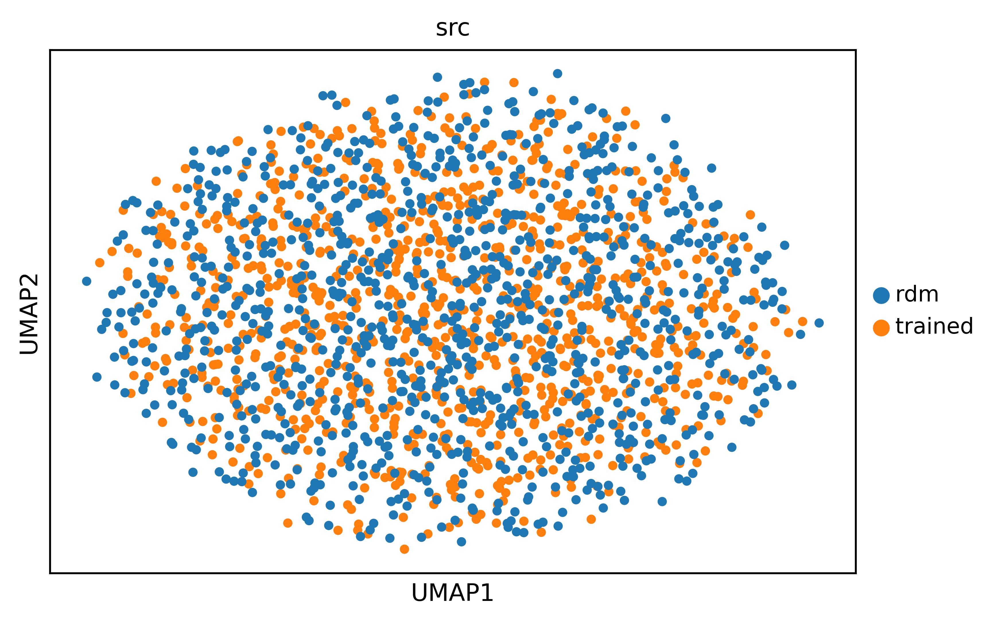

In [34]:
import scanpy as sc
adata = sc.AnnData(np.concatenate((token_emb + seg_emb[1], token_emb_rdm + seg_emb[1])))
adata.obs['gene_name'] = hvgs.index.tolist() + hvgs.index.tolist()
adata.obs['src'] = 1000 * ['trained'] + 1000 * ['rdm']
sc.pp.neighbors(adata)
sc.tl.umap(adata)
sc.pl.umap(adata, color='src')

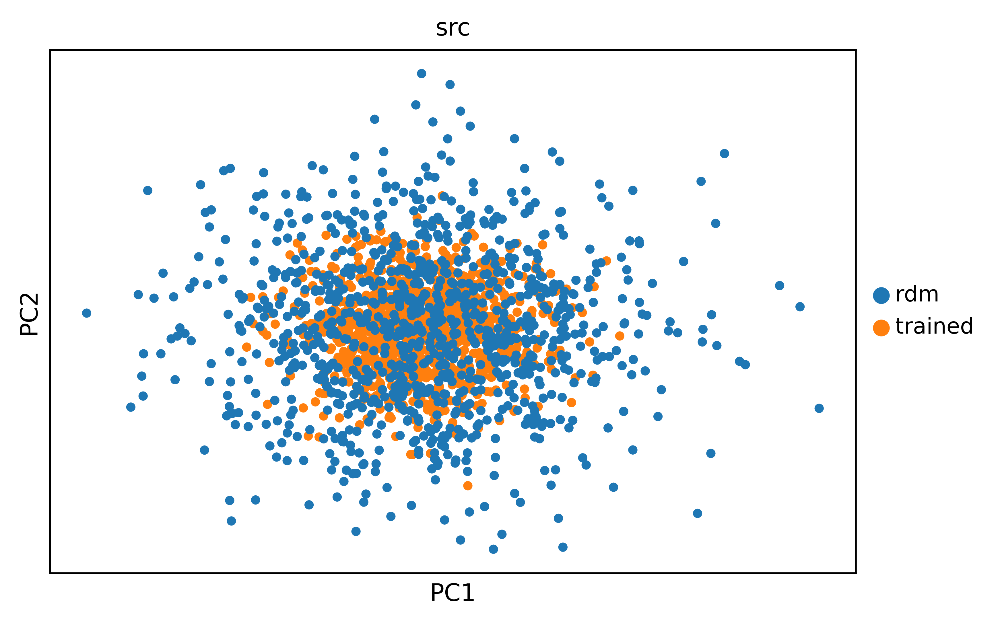

In [35]:
sc.tl.pca(adata)
sc.pl.pca(adata, color='src')

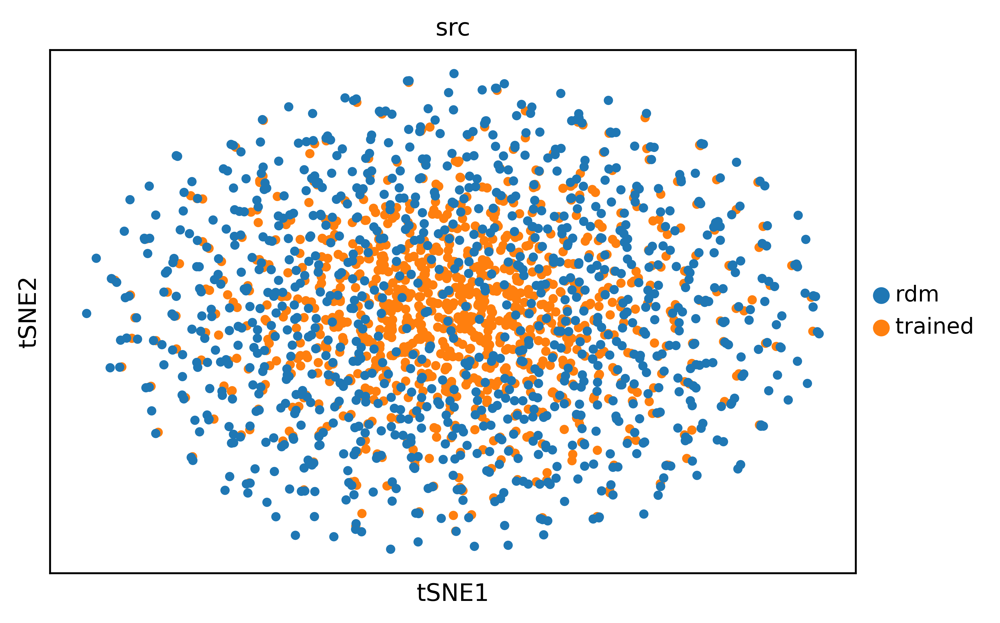

In [39]:
sc.tl.tsne(adata)
sc.pl.tsne(adata, color='src')


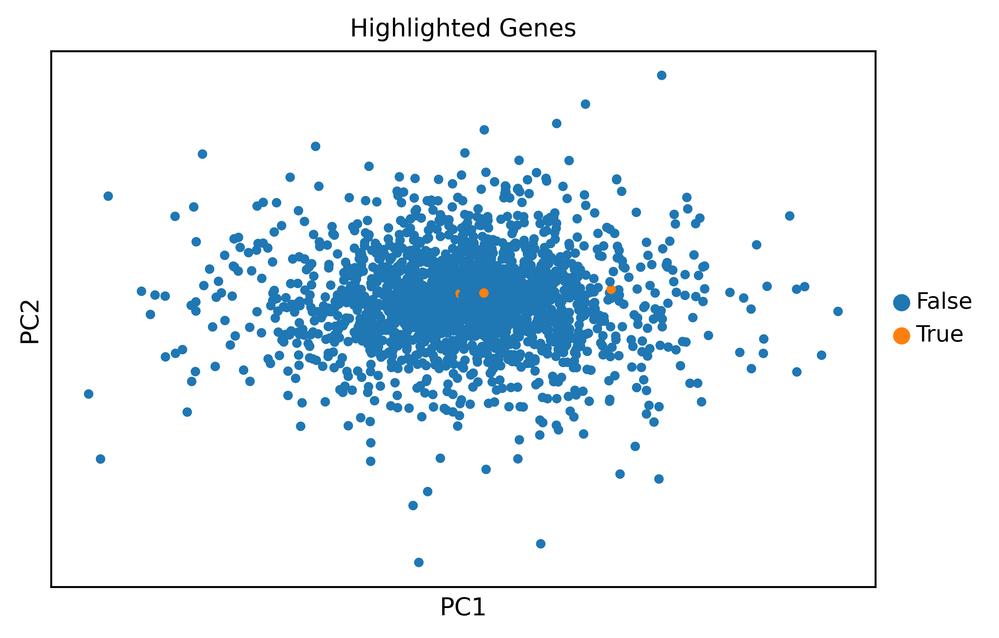

In [61]:
import scanpy as sc

# Assuming you already have your AnnData object `adata` with 'gene_name' column
# Let's say we want to highlight a specific set of genes, for example, genes that are in `hvgs.index`
highlight_genes = ['IL6', 'TNF']  # List of gene names you want to highlight

# Create a new column to store whether a gene name should be highlighted or not
adata.obs['highlight'] = adata.obs['gene_name'].isin(highlight_genes)

# Now, we can plot the UMAP with cells that contain the specified gene names in `highlight_genes`
sc.pp.neighbors(adata)
sc.tl.umap(adata)

# Plot UMAP with highlighted genes
sc.pl.pca(adata, color='highlight', title='Highlighted Genes')

In [ ]:
train_dataset[0]['gene_tokens']

Exception ignored in: <bound method IPythonKernel._clean_thread_parent_frames of <ipykernel.ipkernel.IPythonKernel object at 0x14a47e0447f0>>
Traceback (most recent call last):
  File "/lustre/scratch126/cellgen/team361/sb75/conda/envs/terra_new/lib/python3.10/site-packages/ipykernel/ipkernel.py", line 775, in _clean_thread_parent_frames
    def _clean_thread_parent_frames(
KeyboardInterrupt: 
Exception ignored in: <bound method IPythonKernel._clean_thread_parent_frames of <ipykernel.ipkernel.IPythonKernel object at 0x14a47e0447f0>>
Traceback (most recent call last):
  File "/lustre/scratch126/cellgen/team361/sb75/conda/envs/terra_new/lib/python3.10/site-packages/ipykernel/ipkernel.py", line 775, in _clean_thread_parent_frames
    def _clean_thread_parent_frames(
KeyboardInterrupt: 
Exception ignored in: <bound method IPythonKernel._clean_thread_parent_frames of <ipykernel.ipkernel.IPythonKernel object at 0x14a47e0447f0>>
Traceback (most recent call last):
  File "/lustre/scratch126/ce

In [ ]:
tok = train_dataset[gene_tokens][0]

In [44]:
# Load data
train_dataset, _, test_dataset = prepare_dataset(params)
train_dataset

Loading dataset from disk:   0%|          | 0/32 [00:00<?, ?it/s]

[Dataset({
     features: ['cell_degrees', 'cell_id', 'batch_token', 'gene_panel_token', 'assay_token', 'species_token', 'tissue_token', 'batch_value_token', 'gene_panel_value_token', 'assay_value_token', 'species_value_token', 'tissue_value_token', 'batch_value', 'gene_panel_value', 'assay_value', 'species_value', 'tissue_value', 'gene_tokens', 'gene_expr', 'seg_tokens', 'n_nonzero_tokens', 'cls_tokens'],
     num_rows: 7005489
 }),
 Dataset({
     features: ['cell_degrees', 'cell_id', 'batch_token', 'gene_panel_token', 'assay_token', 'species_token', 'tissue_token', 'batch_value_token', 'gene_panel_value_token', 'assay_value_token', 'species_value_token', 'tissue_value_token', 'batch_value', 'gene_panel_value', 'assay_value', 'species_value', 'tissue_value', 'gene_tokens', 'gene_expr', 'seg_tokens', 'n_nonzero_tokens', 'cls_tokens'],
     num_rows: 7005489
 }),
 Dataset({
     features: ['cell_degrees', 'cell_id', 'batch_token', 'gene_panel_token', 'assay_token', 'species_token', 'ti

In [ ]:
devices=['cuda:0']
world_size=1
os.environ['CUDA_VISIBLE_DEVICES'] = str(devices[rank].split(':')[-1])

logging.basicConfig()
logger = logging.getLogger()
logger.setLevel(logging.INFO if rank == 0 else logging.ERROR)

world_size, rank = init_distributed(rank_and_world_size=(rank, world_size), port=random.randint(40000, 50000))
logger.info(f'Running... (rank: {rank}/{world_size})')

In [ ]:
params['data']['batch_size'] = 4
import gc
gc.collect()
torch.cuda.empty_cache()

In [ ]:
params['mask']['constrain_attention_enc'] = False
params['mask']['constrain_attention_pred'] = False
params['mask']['constrain_attention_type'] = 'segment'
params['mask']['block_masking'] = False
params['mask']['cell_masking'] = True

In [ ]:
### Train model
train(params,
      train_dataset,
      save_folder_path=folder_path,
      LOCAL_RANK=0,)

## 2.1 Benchmarking Test Sets

### 2.1.1 xhs49-1b_1p (Xenium Human Skin Melanoma)

#### 2.1.1.1 Define Config

In [37]:
# Set test batch IDs
params['data']['precomputed_split'] = False
params['data']['test_batch_ids'] = [
    '49_batch0']
params['data']['val_batch_ids'] = None
if 'precomputed_epoch_n_nonzero_tokens' in params['data'].keys():
    del(params['data']['precomputed_epoch_n_nonzero_tokens'])
if 'precomputed_epoch_splits' in params['data'].keys():
    del(params['data']['precomputed_epoch_splits'])

In [38]:
# Set dataset params
dataset_name = 'xhs49-1b_1p'
niche_key = 'niche_name'
latent_leiden_resolution_cell = 1.0
latent_leiden_resolution_neighborhood = 0.4
spot_sizes = [20] * len(params['data']['test_batch_ids'])

#### 2.1.1.2 Run Model Inference

In [39]:
adata = run_inference(dataset_name,
                      params,
                      read_checkpoint,
                      obs_cols=[niche_key],
                      write_to_disk=True)

Loading dataset from disk:   0%|          | 0/32 [00:00<?, ?it/s]

INFO:root:EncoderMultiMaskWrapper(
  (backbone): GeneTransformerCountEncoder(
    (token_embed): Embedding(46814, 384, padding_idx=0)
    (seg_embed): Embedding(12, 384, padding_idx=0)
    (blocks): ModuleList(
      (0-11): 12 x Block(
        (norm1): LayerNorm((384,), eps=1e-06, elementwise_affine=True)
        (attn): Attention(
          (qkv): Linear(in_features=384, out_features=1152, bias=True)
          (attn_drop): Dropout(p=0.0, inplace=False)
          (proj): Linear(in_features=384, out_features=384, bias=True)
          (proj_drop): Dropout(p=0.0, inplace=False)
        )
        (norm2): LayerNorm((384,), eps=1e-06, elementwise_affine=True)
        (mlp): MLP(
          (fc1): Linear(in_features=384, out_features=1536, bias=True)
          (act): GELU(approximate='none')
          (fc2): Linear(in_features=1536, out_features=384, bias=True)
          (drop): Dropout(p=0.0, inplace=False)
        )
      )
    )
    (norm): LayerNorm((384,), eps=1e-06, elementwise_affine=

['encoder', 'predictor', 'target_encoder', 'opt', 'scaler', 'epoch', 'zero_epoch_tracking', 'loss', 'batch_size', 'world_size', 'lr']


0it [00:00, ?it/s]/lustre/scratch126/cellgen/team361/sb75/terra/src/app/infer.py:348: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(dtype=torch.bfloat16,
/lustre/scratch126/cellgen/team361/sb75/conda/envs/terra_new/lib/python3.10/contextlib.py:103: FutureWarning: `torch.backends.cuda.sdp_kernel()` is deprecated. In the future, this context manager will be removed. Please see `torch.nn.attention.sdpa_kernel()` for the new context manager, with updated signature.
  self.gen = func(*args, **kwds)
1707it [25:55,  1.10it/s]
/lustre/scratch126/cellgen/team361/sb75/conda/envs/terra_new/lib/python3.10/site-packages/anndata/_core/aligned_df.py:68: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)


Loading metadata AnnDatas...
Loading datasets: ['49'].
Loading AnnData objects from /lustre/scratch126/cellgen/team361/DATASETS/silver/hst_corpus_70m/xhs49-1b_1p.


/lustre/scratch126/cellgen/team361/sb75/conda/envs/terra_new/lib/python3.10/site-packages/anndata/_core/anndata.py:1145: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  df[key] = c
... storing 'batch' as categorical


#### 2.1.1.3 Plot Embedding Similarity Stats

                   Class 1                   Class 2  Mean Similarity  \
0                 Epidemis                  Epidemis         0.597697   
1                 Epidemis        Superficial dermis         0.549223   
2                 Epidemis       Melanoma+infiltrate         0.295902   
3                 Epidemis                  Melanoma         0.278160   
4                 Epidemis     Immune infiltrate Thi         0.482531   
..                     ...                       ...              ...   
59  Melanoma+blood vessels                  Melanoma         0.981585   
60  Melanoma+blood vessels     Immune infiltrate Thi         0.544463   
61  Melanoma+blood vessels  Immune infiltrate Mac hi         0.685477   
62  Melanoma+blood vessels     Macrophage_fat_region         0.466730   
63  Melanoma+blood vessels    Melanoma+blood vessels         0.989896   

    Variance Similarity  
0              0.065755  
1              0.071621  
2              0.016422  
3              0.01




In [40]:
compute_embedding_similarity(adata,
                             emb_keys=['neighborhood'],
                             label=niche_key,
                             write_to_disk=True)

#### 2.1.1.4 Identify Niches & Cell Types

Target number of unique values: 8.
Leiden resolution: 0.4.


/tmp/ipykernel_1408441/1337707055.py:26: FutureWarning: In the future, the default backend for leiden will be igraph instead of leidenalg.

 To achieve the future defaults please pass: flavor="igraph" and n_iterations=2.  directed must also be False to work with igraph's implementation.
  sc.tl.leiden(adata,


Number of latent clusters 14.
Leiden resolution: 0.35000000000000003.
Number of latent clusters 12.
Leiden resolution: 0.33.
Number of latent clusters 11.
Leiden resolution: 0.329.
Number of latent clusters 12.
Leiden resolution: 0.309.
Number of latent clusters 12.
Leiden resolution: 0.289.
Number of latent clusters 12.
Leiden resolution: 0.26899999999999996.
Number of latent clusters 11.
Leiden resolution: 0.26799999999999996.
Number of latent clusters 12.
Leiden resolution: 0.24799999999999997.
Number of latent clusters 10.
Leiden resolution: 0.24699999999999997.
Number of latent clusters 11.
Leiden resolution: 0.24599999999999997.
Number of latent clusters 10.
Leiden resolution: 0.24499999999999997.
Number of latent clusters 10.
Leiden resolution: 0.24399999999999997.
Number of latent clusters 10.
Leiden resolution: 0.24299999999999997.
Number of latent clusters 11.
Leiden resolution: 0.24199999999999997.
Number of latent clusters 10.
Leiden resolution: 0.24099999999999996.
Number 

/tmp/ipykernel_1408441/1337707055.py:85: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(adata_batch,
/lustre/scratch126/cellgen/team361/sb75/conda/envs/terra_new/lib/python3.10/site-packages/scanpy/plotting/_utils.py:491: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[value_to_plot + "_colors"] = colors_list


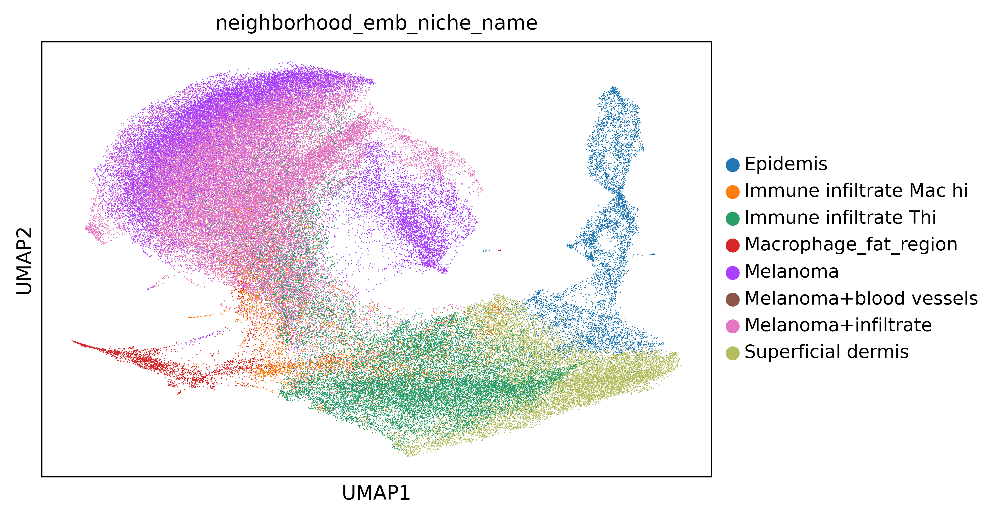

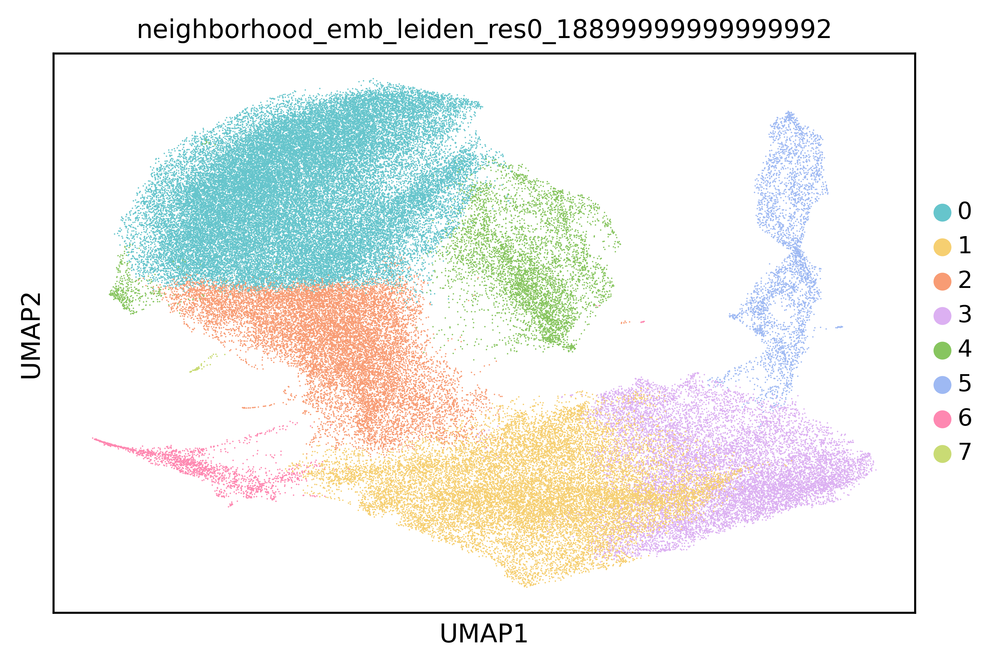

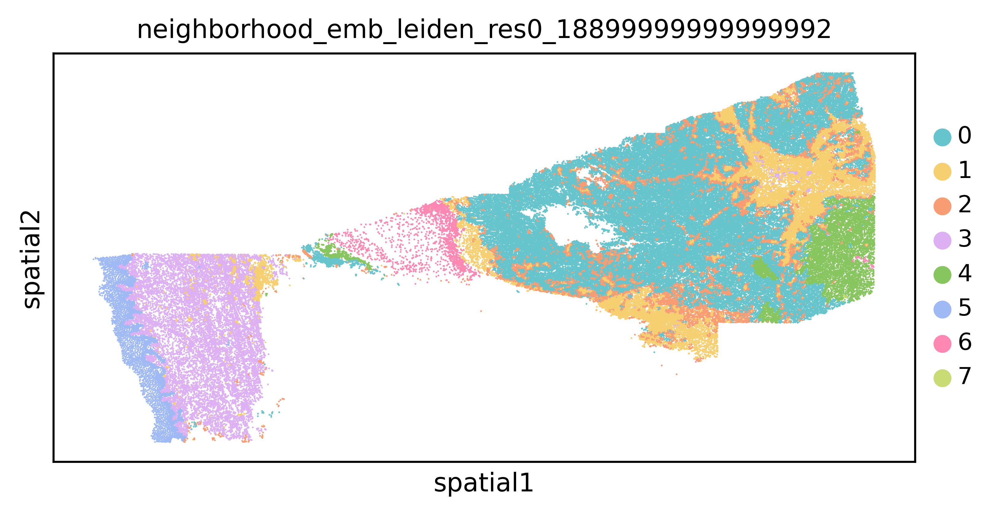

In [41]:
adata = compute_neighborhood_umap(adata,
                                  write_to_disk=True)

adata = compute_latent_clusters(adata,
                                emb_keys=['neighborhood'],
                                obs_col=niche_key,
                                latent_leiden_resolution_cell=latent_leiden_resolution_cell,
                                latent_leiden_resolution_neighborhood=latent_leiden_resolution_neighborhood,
                                write_to_disk=True)

### 2.1.2 xhs1000-39b_1p (Xenium Human Skin Eczema)

#### 2.1.2.1 Define Config

In [42]:
# Set test batch IDs
params['data']['precomputed_split'] = False
params['data']['test_batch_ids'] = [
    '1000_batch11',
    '1000_batch19',
    '1000_batch32']
params['data']['val_batch_ids'] = None
if 'precomputed_epoch_n_nonzero_tokens' in params['data'].keys():
    del(params['data']['precomputed_epoch_n_nonzero_tokens'])
if 'precomputed_epoch_splits' in params['data'].keys():
    del(params['data']['precomputed_epoch_splits'])

In [43]:
# Set dataset params
dataset_name = 'xhs1000-39b_1p'
niche_key = 'niche_type'
batch_key = 'sample'
latent_leiden_resolution_cell = 1.0
latent_leiden_resolution_neighborhood = 0.4
spot_sizes = [20] * len(params['data']['test_batch_ids'])

#### 2.1.2.2 Run Model Inference

In [44]:
adata = run_inference(dataset_name,
                      params,
                      read_checkpoint,
                      obs_cols=[niche_key],
                      write_to_disk=True)

Loading dataset from disk:   0%|          | 0/32 [00:00<?, ?it/s]

INFO:root:EncoderMultiMaskWrapper(
  (backbone): GeneTransformerCountEncoder(
    (token_embed): Embedding(46814, 384, padding_idx=0)
    (seg_embed): Embedding(12, 384, padding_idx=0)
    (blocks): ModuleList(
      (0-11): 12 x Block(
        (norm1): LayerNorm((384,), eps=1e-06, elementwise_affine=True)
        (attn): Attention(
          (qkv): Linear(in_features=384, out_features=1152, bias=True)
          (attn_drop): Dropout(p=0.0, inplace=False)
          (proj): Linear(in_features=384, out_features=384, bias=True)
          (proj_drop): Dropout(p=0.0, inplace=False)
        )
        (norm2): LayerNorm((384,), eps=1e-06, elementwise_affine=True)
        (mlp): MLP(
          (fc1): Linear(in_features=384, out_features=1536, bias=True)
          (act): GELU(approximate='none')
          (fc2): Linear(in_features=1536, out_features=384, bias=True)
          (drop): Dropout(p=0.0, inplace=False)
        )
      )
    )
    (norm): LayerNorm((384,), eps=1e-06, elementwise_affine=

['encoder', 'predictor', 'target_encoder', 'opt', 'scaler', 'epoch', 'zero_epoch_tracking', 'loss', 'batch_size', 'world_size', 'lr']


0it [00:00, ?it/s]/lustre/scratch126/cellgen/team361/sb75/terra/src/app/infer.py:348: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(dtype=torch.bfloat16,
/lustre/scratch126/cellgen/team361/sb75/conda/envs/terra_new/lib/python3.10/contextlib.py:103: FutureWarning: `torch.backends.cuda.sdp_kernel()` is deprecated. In the future, this context manager will be removed. Please see `torch.nn.attention.sdpa_kernel()` for the new context manager, with updated signature.
  self.gen = func(*args, **kwds)
839it [12:47,  1.09it/s]
/lustre/scratch126/cellgen/team361/sb75/conda/envs/terra_new/lib/python3.10/site-packages/anndata/_core/aligned_df.py:68: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)


Loading metadata AnnDatas...
Loading datasets: ['1000'].
Loading AnnData objects from /lustre/scratch126/cellgen/team361/DATASETS/silver/hst_corpus_70m/xhs1000-39b_1p.


/lustre/scratch126/cellgen/team361/sb75/conda/envs/terra_new/lib/python3.10/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")
/lustre/scratch126/cellgen/team361/sb75/conda/envs/terra_new/lib/python3.10/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")
/lustre/scratch126/cellgen/team361/sb75/conda/envs/terra_new/lib/python3.10/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")
/lustre/scratch126/cellgen/team361/sb75/conda/envs/terra_new/lib/python3.10/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.w

#### 2.1.2.3 Plot Embedding Similarity Stats

In [45]:
compute_embedding_similarity(adata,
                             emb_keys=['neighborhood'],
                             label=niche_key,
                             write_to_disk=True)

                                Class 1                             Class 2  \
0    Basal epidermis/superficial dermis  Basal epidermis/superficial dermis   
1    Basal epidermis/superficial dermis                            KC_T2_LC   
2    Basal epidermis/superficial dermis                                  KC   
3    Basal epidermis/superficial dermis            Perivascular superficial   
4    Basal epidermis/superficial dermis                 Interstitial stroma   
..                                  ...                                 ...   
139                   Epidermis with T2                       Schwann_KC_HF   
140                   Epidermis with T2                              Muscle   
141                   Epidermis with T2                        Sweat gland1   
142                   Epidermis with T2                        Sweat gland2   
143                   Epidermis with T2                   Epidermis with T2   

     Mean Similarity  Variance Similarity  
0      

#### 2.1.2.4 Identify Niches & Cell Types

Target number of unique values: 12.
Leiden resolution: 0.4.
Number of latent clusters 25.
Leiden resolution: 0.30000000000000004.
Number of latent clusters 21.
Leiden resolution: 0.20000000000000004.
Number of latent clusters 17.
Leiden resolution: 0.18000000000000005.
Number of latent clusters 20.
Leiden resolution: 0.13000000000000006.
Number of latent clusters 13.
Leiden resolution: 0.12900000000000006.
Number of latent clusters 14.
Leiden resolution: 0.12800000000000006.
Number of latent clusters 14.
Leiden resolution: 0.12700000000000006.
Number of latent clusters 14.
Leiden resolution: 0.12600000000000006.
Number of latent clusters 12.
NMI is 0.6445771791016223. ARI is 0.46213392583126994.


/tmp/ipykernel_1408441/1337707055.py:85: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(adata_batch,
/lustre/scratch126/cellgen/team361/sb75/conda/envs/terra_new/lib/python3.10/site-packages/scanpy/plotting/_utils.py:491: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[value_to_plot + "_colors"] = colors_list


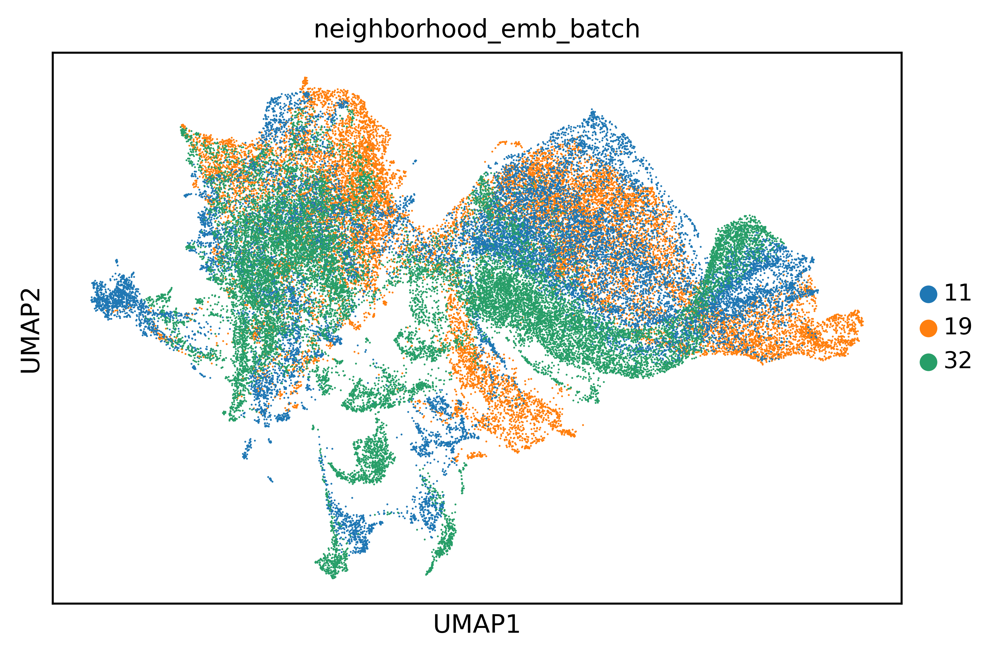

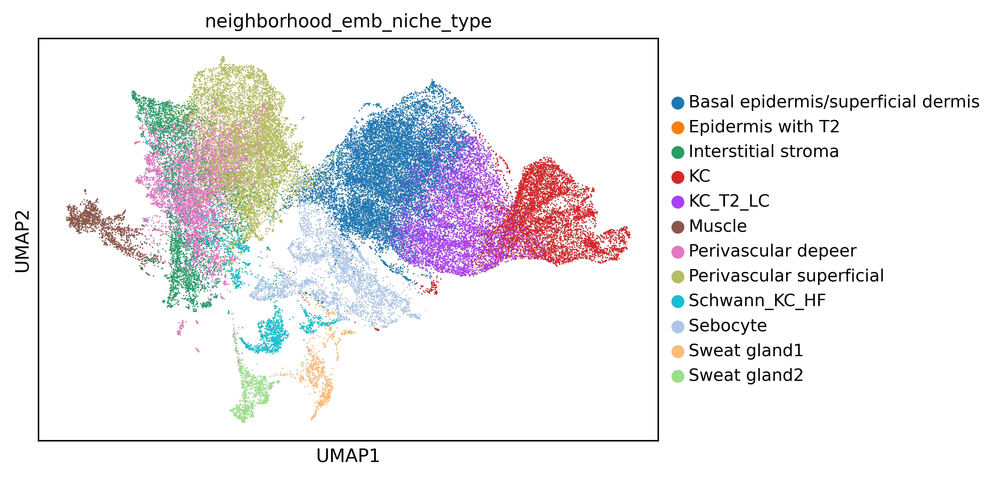

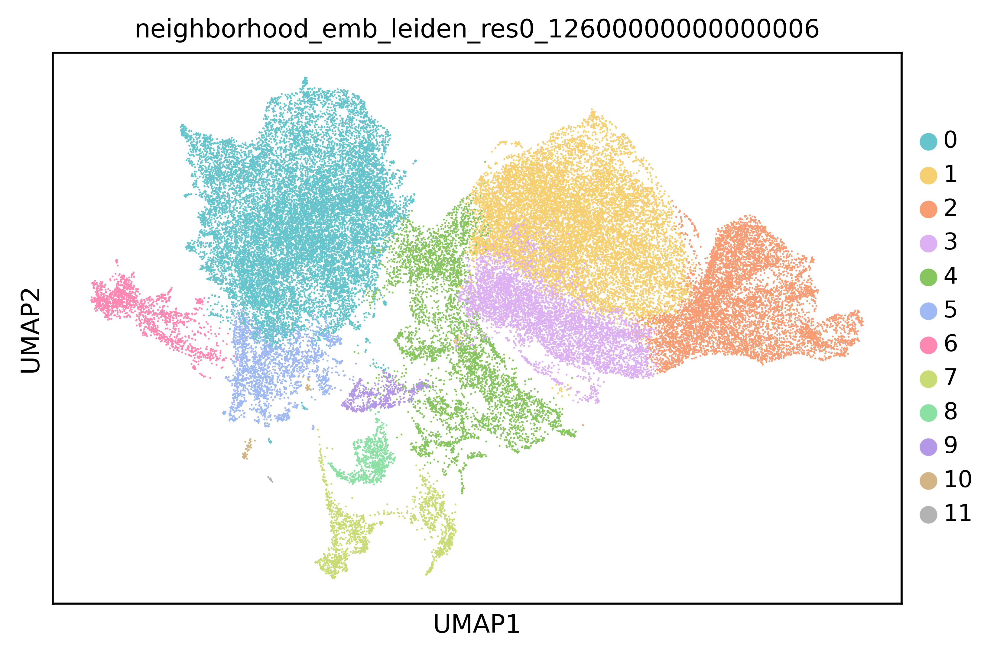

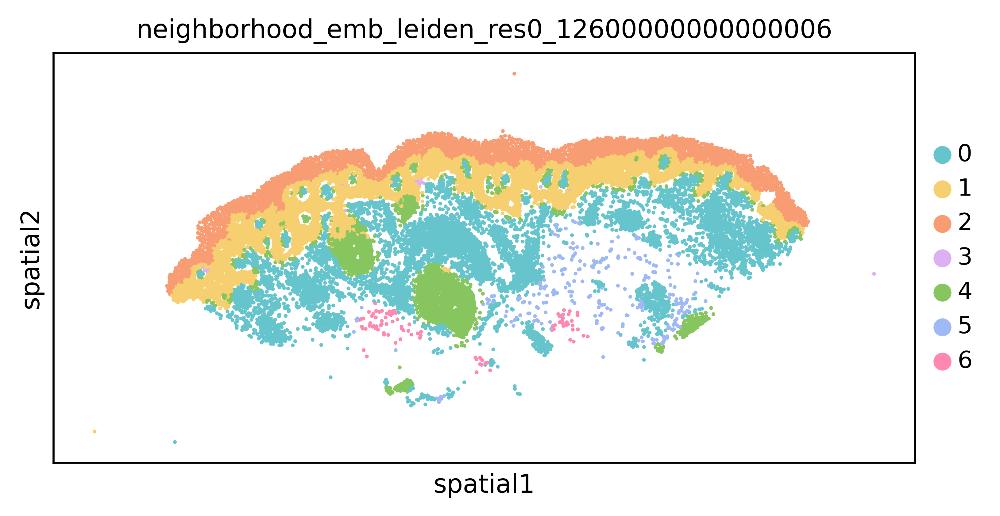

/tmp/ipykernel_1408441/1337707055.py:85: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(adata_batch,
/lustre/scratch126/cellgen/team361/sb75/conda/envs/terra_new/lib/python3.10/site-packages/scanpy/plotting/_utils.py:491: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[value_to_plot + "_colors"] = colors_list


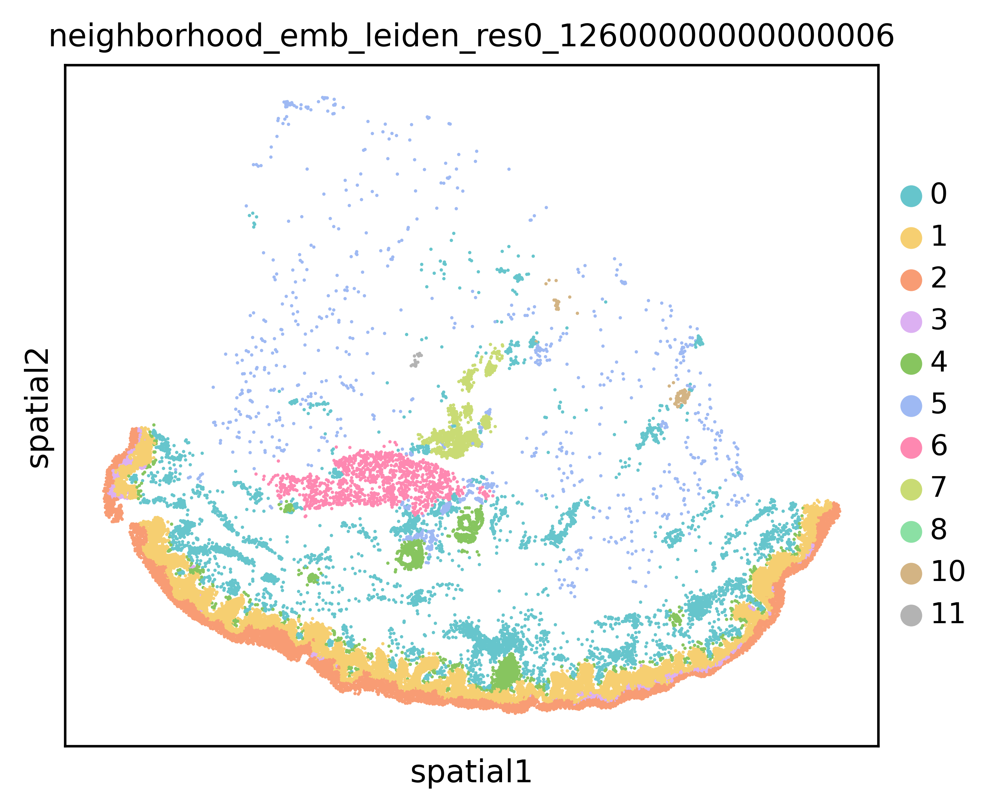

/tmp/ipykernel_1408441/1337707055.py:85: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(adata_batch,
/lustre/scratch126/cellgen/team361/sb75/conda/envs/terra_new/lib/python3.10/site-packages/scanpy/plotting/_utils.py:491: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[value_to_plot + "_colors"] = colors_list


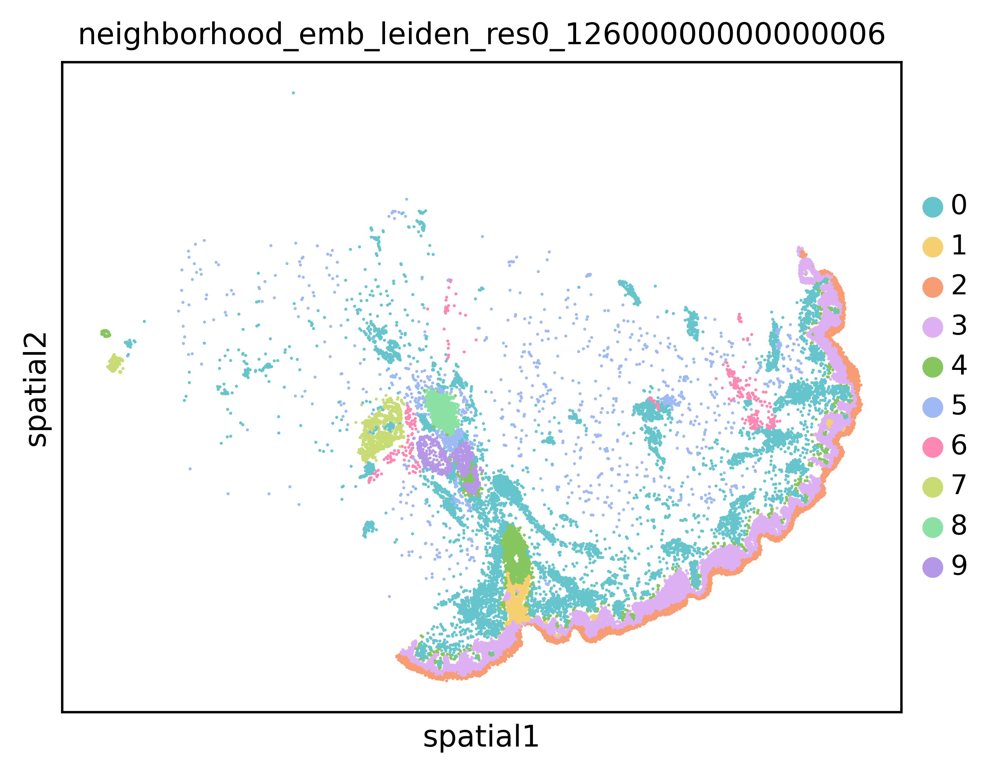

In [46]:
adata = compute_neighborhood_umap(adata,
                                  write_to_disk=True)

adata = compute_latent_clusters(adata,
                                emb_keys=['neighborhood'],
                                obs_col=niche_key,
                                latent_leiden_resolution_cell=latent_leiden_resolution_cell,
                                latent_leiden_resolution_neighborhood=latent_leiden_resolution_neighborhood,
                                write_to_disk=True)

### 2.1.3 xhk1007-41b_1p (Xenium Human Kidney RCC)

#### 2.1.3.1 Define Config

In [47]:
# Set test batch IDs
params['data']['precomputed_split'] = False
params['data']['test_batch_ids'] = [
     '1007_batch1',
     '1007_batch14'
]
params['data']['val_batch_ids'] = None
if 'precomputed_epoch_n_nonzero_tokens' in params['data'].keys():
    del(params['data']['precomputed_epoch_n_nonzero_tokens'])
if 'precomputed_epoch_splits' in params['data'].keys():
    del(params['data']['precomputed_epoch_splits'])

In [48]:
# Set dataset params
dataset_name = 'xhk1007-41b_1p'
cell_type_key = 'level_1_cell_type'
batch_key = 'batch'
latent_leiden_resolution_cell = 0.75
latent_leiden_resolution_neighborhood = 0.2
spot_sizes = [30] * len(params['data']['test_batch_ids'])

#### 2.1.3.2 Run Model Inference

In [49]:
adata = run_inference(dataset_name,
                      params,
                      read_checkpoint,
                      obs_cols=[cell_type_key],
                      write_to_disk=True)

Loading dataset from disk:   0%|          | 0/32 [00:00<?, ?it/s]

INFO:root:EncoderMultiMaskWrapper(
  (backbone): GeneTransformerCountEncoder(
    (token_embed): Embedding(46814, 384, padding_idx=0)
    (seg_embed): Embedding(12, 384, padding_idx=0)
    (blocks): ModuleList(
      (0-11): 12 x Block(
        (norm1): LayerNorm((384,), eps=1e-06, elementwise_affine=True)
        (attn): Attention(
          (qkv): Linear(in_features=384, out_features=1152, bias=True)
          (attn_drop): Dropout(p=0.0, inplace=False)
          (proj): Linear(in_features=384, out_features=384, bias=True)
          (proj_drop): Dropout(p=0.0, inplace=False)
        )
        (norm2): LayerNorm((384,), eps=1e-06, elementwise_affine=True)
        (mlp): MLP(
          (fc1): Linear(in_features=384, out_features=1536, bias=True)
          (act): GELU(approximate='none')
          (fc2): Linear(in_features=1536, out_features=384, bias=True)
          (drop): Dropout(p=0.0, inplace=False)
        )
      )
    )
    (norm): LayerNorm((384,), eps=1e-06, elementwise_affine=

['encoder', 'predictor', 'target_encoder', 'opt', 'scaler', 'epoch', 'zero_epoch_tracking', 'loss', 'batch_size', 'world_size', 'lr']


0it [00:00, ?it/s]/lustre/scratch126/cellgen/team361/sb75/terra/src/app/infer.py:348: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(dtype=torch.bfloat16,
/lustre/scratch126/cellgen/team361/sb75/conda/envs/terra_new/lib/python3.10/contextlib.py:103: FutureWarning: `torch.backends.cuda.sdp_kernel()` is deprecated. In the future, this context manager will be removed. Please see `torch.nn.attention.sdpa_kernel()` for the new context manager, with updated signature.
  self.gen = func(*args, **kwds)
2122it [32:10,  1.10it/s]
/lustre/scratch126/cellgen/team361/sb75/conda/envs/terra_new/lib/python3.10/site-packages/anndata/_core/aligned_df.py:68: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)


Loading metadata AnnDatas...
Loading datasets: ['1007'].
Loading AnnData objects from /lustre/scratch126/cellgen/team361/DATASETS/silver/hst_corpus_70m/xhk1007-CV5-41b_1p.


/lustre/scratch126/cellgen/team361/sb75/conda/envs/terra_new/lib/python3.10/site-packages/anndata/_core/aligned_df.py:68: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)
/lustre/scratch126/cellgen/team361/sb75/conda/envs/terra_new/lib/python3.10/site-packages/anndata/_core/aligned_df.py:68: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)
/lustre/scratch126/cellgen/team361/sb75/conda/envs/terra_new/lib/python3.10/site-packages/anndata/_core/aligned_df.py:68: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)
/lustre/scratch126/cellgen/team361/sb75/conda/envs/terra_new/lib/python3.10/site-packages/anndata/_core/aligned_df.py:68: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificat

... (12 outputs left out)

Loading AnnData objects from /lustre/scratch126/cellgen/team361/DATASETS/silver/hst_corpus_70m/xhk1007-CV6-41b_1p.


/lustre/scratch126/cellgen/team361/sb75/conda/envs/terra_new/lib/python3.10/site-packages/anndata/_core/aligned_df.py:68: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)
/lustre/scratch126/cellgen/team361/sb75/conda/envs/terra_new/lib/python3.10/site-packages/anndata/_core/aligned_df.py:68: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)
/lustre/scratch126/cellgen/team361/sb75/conda/envs/terra_new/lib/python3.10/site-packages/anndata/_core/aligned_df.py:68: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)
/lustre/scratch126/cellgen/team361/sb75/conda/envs/terra_new/lib/python3.10/site-packages/anndata/_core/aligned_df.py:68: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificat

Loading AnnData objects from /lustre/scratch126/cellgen/team361/DATASETS/silver/hst_corpus_70m/xhk1007-CV1-41b_1p.


/lustre/scratch126/cellgen/team361/sb75/conda/envs/terra_new/lib/python3.10/site-packages/anndata/_core/aligned_df.py:68: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)
/lustre/scratch126/cellgen/team361/sb75/conda/envs/terra_new/lib/python3.10/site-packages/anndata/_core/aligned_df.py:68: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)
/lustre/scratch126/cellgen/team361/sb75/conda/envs/terra_new/lib/python3.10/site-packages/anndata/_core/aligned_df.py:68: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)
/lustre/scratch126/cellgen/team361/sb75/conda/envs/terra_new/lib/python3.10/site-packages/anndata/_core/aligned_df.py:68: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificat

#### 2.1.3.3 Plot Embedding Similarity Stats

        Class 1      Class 2  Mean Similarity  Variance Similarity
0       Myeloid      Myeloid         0.885325             0.007054
1       Myeloid   Epithelium         0.843702             0.012402
2       Myeloid  Endothelium         0.864832             0.008030
3       Myeloid     Lymphoid         0.866965             0.008262
4       Myeloid       Stroma         0.868445             0.007295
5    Epithelium      Myeloid         0.843704             0.012402
6    Epithelium   Epithelium         0.896284             0.009122
7    Epithelium  Endothelium         0.866474             0.007082
8    Epithelium     Lymphoid         0.817748             0.016630
9    Epithelium       Stroma         0.846576             0.010142
10  Endothelium      Myeloid         0.864838             0.008030
11  Endothelium   Epithelium         0.866479             0.007082
12  Endothelium  Endothelium         0.898573             0.005588
13  Endothelium     Lymphoid         0.841754             0.01




In [50]:
compute_embedding_similarity(adata,
                             emb_keys=['cell'],
                             label=cell_type_key,
                             write_to_disk=True)

#### 2.1.3.4 Identify Niches & Cell Types

In [ ]:
adata = compute_neighborhood_umap(adata,
                                  write_to_disk=True)

adata = compute_latent_clusters(adata,
                                emb_keys=['cell'],
                                obs_col=cell_type_key,
                                latent_leiden_resolution_cell=latent_leiden_resolution_cell,
                                latent_leiden_resolution_neighborhood=latent_leiden_resolution_neighborhood,
                                write_to_disk=True)

Target number of unique values: 5.
Leiden resolution: 0.75.
Number of latent clusters 14.
Leiden resolution: 0.65.
Number of latent clusters 14.
Leiden resolution: 0.55.
Number of latent clusters 13.
Leiden resolution: 0.5.
Number of latent clusters 12.
Leiden resolution: 0.45.
Number of latent clusters 10.
Leiden resolution: 0.43.
Number of latent clusters 10.
Leiden resolution: 0.41.
Number of latent clusters 10.
Leiden resolution: 0.38999999999999996.
Number of latent clusters 8.
Leiden resolution: 0.38899999999999996.
Number of latent clusters 10.
Leiden resolution: 0.36899999999999994.
Number of latent clusters 8.
Leiden resolution: 0.36799999999999994.
Number of latent clusters 8.
Leiden resolution: 0.36699999999999994.
Number of latent clusters 8.
Leiden resolution: 0.36599999999999994.
Number of latent clusters 8.
Leiden resolution: 0.36499999999999994.
Number of latent clusters 8.
Leiden resolution: 0.36399999999999993.
Number of latent clusters 8.
Leiden resolution: 0.3629999

### 2.1.4 xhb1002-75b_3p (Xenium Human Brain GBM)

#### 2.1.4.1 Define Config

In [ ]:
# Set test batch IDs
params['data']['precomputed_split'] = False
params['data']['test_batch_ids'] = [
    '1002_batch3',
    '1002_batch15'
    '1002_batch27']
params['data']['val_batch_ids'] = None
if 'precomputed_epoch_n_nonzero_tokens' in params['data'].keys():
    del(params['data']['precomputed_epoch_n_nonzero_tokens'])
if 'precomputed_epoch_splits' in params['data'].keys():
    del(params['data']['precomputed_epoch_splits'])

In [ ]:
# Set dataset params
dataset_name = 'xhb1002-75b_3p'
cell_type_key = 'leiden_log1pnorm_res-1'
batch_key = 'batch'
latent_leiden_resolution_cell = 1.0
latent_leiden_resolution_neighborhood = 0.4
spot_sizes = [30] * len(params['data']['test_batch_ids'])

#### 2.1.4.2 Run Model Inference

In [ ]:
adata = run_inference(dataset_name,
                      params,
                      read_checkpoint,
                      obs_cols=[cell_type_key],
                      write_to_disk=True)

#### 2.1.4.3 Plot Embedding Similarity Stats

In [ ]:
compute_embedding_similarity(adata,
                             emb_keys=['cell'],
                             label=cell_type_key,
                             write_to_disk=True)

#### 2.1.4.4 Identify Niches & Cell Types

In [ ]:
adata = compute_neighborhood_umap(adata,
                                  write_to_disk=True)

adata = compute_latent_clusters(adata,
                                emb_keys=['cell'],
                                obs_col=cell_type_key,
                                latent_leiden_resolution_cell=latent_leiden_resolution_cell,
                                latent_leiden_resolution_neighborhood=latent_leiden_resolution_neighborhood,
                                write_to_disk=True)

### 2.1.5 chl59-8b_1p (NanoString CosMx Human Lung NSCLC)

#### 2.1.5.1 Define Config

In [ ]:
# Set test batch IDs
params['data']['precomputed_split'] = False
params['data']['test_batch_ids'] = [
    '59_batch0',
    #'59_batch3', # unannotated
    '59_batch6',
    '59_batch7',
    #'59_batch2', # unannotated
    '59_batch4',
    '59_batch1',
    '59_batch5']
params['data']['val_batch_ids'] = None
if 'precomputed_epoch_n_nonzero_tokens' in params['data'].keys():
    del(params['data']['precomputed_epoch_n_nonzero_tokens'])
if 'precomputed_epoch_splits' in params['data'].keys():
    del(params['data']['precomputed_epoch_splits'])

In [ ]:
# Set dataset params
dataset_name = 'chl59-8b_1p'
niche_key = 'niche'
batch_key = 'batch'
latent_leiden_resolution_cell = 1.0
latent_leiden_resolution_neighborhood = 0.6
spot_sizes = [80] * len(params['data']['test_batch_ids'])

#### 2.1.5.2 Run Model Inference

In [ ]:
adata = run_inference(dataset_name,
                      params,
                      read_checkpoint,
                      obs_cols=[niche_key],
                      write_to_disk=True)

#### 2.1.5.3 Plot Embedding Similarity Stats

In [ ]:
compute_embedding_similarity(adata,
                             emb_keys=['neighborhood'],
                             label=niche_key,
                             write_to_disk=True)

#### 2.1.5.4 Identify Niches & Cell Types

In [ ]:
adata = compute_neighborhood_umap(adata,
                                  write_to_disk=True)

adata = compute_latent_clusters(adata,
                                emb_keys=['neighborhood'],
                                obs_col=niche_key,
                                latent_leiden_resolution_cell=latent_leiden_resolution_cell,
                                latent_leiden_resolution_neighborhood=latent_leiden_resolution_neighborhood,
                                write_to_disk=True)

### 2.1.6 chr78-11b_1p (ISS Cartana Human Reproductive Tract)

#### 2.1.6.1 Define Config

In [ ]:
# Set test batch IDs
params['data']['precomputed_split'] = False
params['data']['test_batch_ids'] = [
    '78_batch3',
    '78_batch10',
    '78_batch1',
    '78_batch0',
    '78_batch2',
    '78_batch6',
    '78_batch7',
    '78_batch9',
    '78_batch8',
    '78_batch4',
    '78_batch5']
params['data']['val_batch_ids'] = None
if 'precomputed_epoch_n_nonzero_tokens' in params['data'].keys():
    del(params['data']['precomputed_epoch_n_nonzero_tokens'])
if 'precomputed_epoch_splits' in params['data'].keys():
    del(params['data']['precomputed_epoch_splits'])

In [ ]:
# Set dataset params
dataset_name = 'chr78-11b_1p'
niche_key = 'broad_anatomy'
batch_key = 'batch'
latent_leiden_resolution_cell = 1.0
latent_leiden_resolution_neighborhood = 0.4
spot_sizes = [1920 * 0.093] * len(params['data']['test_batch_ids'])

#### 2.1.6.2 Run Model Inference

In [ ]:
adata = run_inference(dataset_name,
                      params,
                      read_checkpoint,
                      obs_cols=[niche_key],
                      write_to_disk=True)

#### 2.1.6.3 Plot Embedding Similarity Stats

In [ ]:
compute_embedding_similarity(adata,
                             emb_keys=['neighborhood'],
                             label=niche_key,
                             write_to_disk=True)

#### 2.1.6.4 Identify Niches & Cell Types

In [ ]:
adata = compute_neighborhood_umap(adata,
                                  write_to_disk=True)

adata = compute_latent_clusters(adata,
                                emb_keys=['neighborhood'],
                                obs_col=niche_key,
                                latent_leiden_resolution_cell=latent_leiden_resolution_cell,
                                latent_leiden_resolution_neighborhood=latent_leiden_resolution_neighborhood,
                                write_to_disk=True)

## 2.2 Full Corpus

In [ ]:
# Load token dict
with open(token_dict_path, 'rb') as f:
    token_dict = pickle.load(f)

token_dict_reverse =  {value: key for key, value in token_dict.items()}

In [ ]:
# Load dataset
dataset = load_from_disk(params['data']['tokenized_data_folder_path'])

In [ ]:
# Set inference params
layer = params['meta']['enc_depth']
exclude_unshared_tokens = False # True, False
agg_type = 'avg' # 'avg', 'weighted_avg', 'cls'
latent_leiden_resolution = 0.5 # 0.1, 0.5
latent_cluster_key = f'leiden_res{str(latent_leiden_resolution).replace(".", "_")}'

In [ ]:
# Subset dataset
step_size = 2000000
steps = int(np.ceil(len(dataset)/step_size))

dataset_subsets = []

for i in range(steps):
    if ((i+1)*step_size) > len(dataset):
        end_step = len(dataset)
    else:
        end_step = (i+1)*step_size
    dataset_subsets.append(dataset.select(np.arange(i*step_size, end_step)))

del dataset

In [ ]:
# Get batches for current dataset subset
# Iteration 6 and 26 need 1TB RAM
for i, dataset_subset in enumerate(dataset_subsets):
    if i > 5:
        continue
    print(f'Iteration: {i}')
    
    # Get batches
    batches = list(set([token_dict_reverse[batch_value[0]] for batch_value in dataset_subset['batch_value_token']]))
    print(f'Batches: {batches}')
    
    # Get dataset IDs
    dataset_ids = list(set([batch.split('_')[1] for batch in batches]))
    print(f'Dataset IDs: {dataset_ids}')

    # Run model inference
    adata = infer(params,
                  dataset_subset,
                  load_folder_path=folder_path,
                  dataset_ids=dataset_ids,
                  obs_cols=None,
                  uns_cols=['assay', 'tissue'],
                  agg_type=agg_type,
                  masked_tokens=None,
                  agg_excluded_tokens=None,
                  cell_gene_ids=[],
                  neighborhood_gene_ids=[]
                 )
    
    # Save adata
    adata.write(f'{folder_path}/adata_{read_checkpoint.split("-")[1].split(".")[0]}_{step_size}_{i}.h5ad')
    del adata

In [ ]:
# Get batches for current dataset subset
# Iteration 6 and 26 need 1TB RAM
for i, dataset_subset in enumerate(dataset_subsets):
    if i != 6:
        continue
    print(f'Iteration: {i}')
    
    # Get batches
    batches = list(set([token_dict_reverse[batch_value[0]] for batch_value in dataset_subset['batch_value_token']]))
    print(f'Batches: {batches}')
    
    # Get dataset IDs
    dataset_ids = list(set([batch.split('_')[1] for batch in batches]))
    print(f'Dataset IDs: {dataset_ids}')

    # Run model inference
    adata = infer(params,
                  dataset_subset,
                  load_folder_path=folder_path,
                  dataset_ids=dataset_ids,
                  obs_cols=None,
                  uns_cols=['assay', 'tissue'],
                  agg_type=agg_type,
                  masked_tokens=None,
                  agg_excluded_tokens=None,
                  cell_gene_ids=[],
                  neighborhood_gene_ids=[]
                 )
    
    # Save adata
    adata.write(f'{folder_path}/adata_{read_checkpoint.split("-")[1].split(".")[0]}_{step_size}_{i}.h5ad')
    del adata

In [ ]:
# Get batches for current dataset subset
# Iteration 6 and 26 need 1TB RAM
for i, dataset_subset in enumerate(dataset_subsets):
    if i < 7:
        continue
    if i > 12:
        continue
    print(f'Iteration: {i}')
    
    # Get batches
    batches = list(set([token_dict_reverse[batch_value[0]] for batch_value in dataset_subset['batch_value_token']]))
    print(f'Batches: {batches}')
    
    # Get dataset IDs
    dataset_ids = list(set([batch.split('_')[1] for batch in batches]))
    print(f'Dataset IDs: {dataset_ids}')

    # Run model inference
    adata = infer(params,
                  dataset_subset,
                  load_folder_path=folder_path,
                  dataset_ids=dataset_ids,
                  obs_cols=None,
                  uns_cols=['assay', 'tissue'],
                  agg_type=agg_type,
                  masked_tokens=None,
                  agg_excluded_tokens=None,
                  cell_gene_ids=[],
                  neighborhood_gene_ids=[]
                 )
    
    # Save adata
    adata.write(f'{folder_path}/adata_{read_checkpoint.split("-")[1].split(".")[0]}_{step_size}_{i}.h5ad')
    del adata

In [ ]:
# Get batches for current dataset subset
# Iteration 6 and 26 need 1TB RAM
for i, dataset_subset in enumerate(dataset_subsets):
    if i < 13:
        continue
    if i > 18:
        continue
    print(f'Iteration: {i}')
    
    # Get batches
    batches = list(set([token_dict_reverse[batch_value[0]] for batch_value in dataset_subset['batch_value_token']]))
    print(f'Batches: {batches}')
    
    # Get dataset IDs
    dataset_ids = list(set([batch.split('_')[1] for batch in batches]))
    print(f'Dataset IDs: {dataset_ids}')

    # Run model inference
    adata = infer(params,
                  dataset_subset,
                  load_folder_path=folder_path,
                  dataset_ids=dataset_ids,
                  obs_cols=None,
                  uns_cols=['assay', 'tissue'],
                  agg_type=agg_type,
                  masked_tokens=None,
                  agg_excluded_tokens=None,
                  cell_gene_ids=[],
                  neighborhood_gene_ids=[]
                 )
    
    # Save adata
    adata.write(f'{folder_path}/adata_{read_checkpoint.split("-")[1].split(".")[0]}_{step_size}_{i}.h5ad')
    del adata

In [ ]:
# Get batches for current dataset subset
# Iteration 6 and 26 need 1TB RAM
for i, dataset_subset in enumerate(dataset_subsets):
    if i < 19:
        continue
    if i > 25:
        continue
    print(f'Iteration: {i}')
    
    # Get batches
    batches = list(set([token_dict_reverse[batch_value[0]] for batch_value in dataset_subset['batch_value_token']]))
    print(f'Batches: {batches}')
    
    # Get dataset IDs
    dataset_ids = list(set([batch.split('_')[1] for batch in batches]))
    print(f'Dataset IDs: {dataset_ids}')

    # Run model inference
    adata = infer(params,
                  dataset_subset,
                  load_folder_path=folder_path,
                  dataset_ids=dataset_ids,
                  obs_cols=None,
                  uns_cols=['assay', 'tissue'],
                  agg_type=agg_type,
                  masked_tokens=None,
                  agg_excluded_tokens=None,
                  cell_gene_ids=[],
                  neighborhood_gene_ids=[]
                 )
    
    # Save adata
    adata.write(f'{folder_path}/adata_{read_checkpoint.split("-")[1].split(".")[0]}_{step_size}_{i}.h5ad')
    del adata

In [ ]:
# Get batches for current dataset subset
# Iteration 6 and 26 need 1TB RAM
for i, dataset_subset in enumerate(dataset_subsets):
    if i != 26:
        continue
    print(f'Iteration: {i}')
    
    # Get batches
    batches = list(set([token_dict_reverse[batch_value[0]] for batch_value in dataset_subset['batch_value_token']]))
    print(f'Batches: {batches}')
    
    # Get dataset IDs
    dataset_ids = list(set([batch.split('_')[1] for batch in batches]))
    print(f'Dataset IDs: {dataset_ids}')

    # Run model inference
    adata = infer(params,
                  dataset_subset,
                  load_folder_path=folder_path,
                  dataset_ids=dataset_ids,
                  obs_cols=None,
                  uns_cols=['assay', 'tissue'],
                  agg_type=agg_type,
                  masked_tokens=None,
                  agg_excluded_tokens=None,
                  cell_gene_ids=[],
                  neighborhood_gene_ids=[]
                 )
    
    # Save adata
    adata.write(f'{folder_path}/adata_{read_checkpoint.split("-")[1].split(".")[0]}_{step_size}_{i}.h5ad')
    del adata

In [ ]:
# Get batches for current dataset subset
# Iteration 6 and 26 need 1TB RAM
for i, dataset_subset in enumerate(dataset_subsets):
    if i < 27:
        continue
    print(f'Iteration: {i}')
    
    # Get batches
    batches = list(set([token_dict_reverse[batch_value[0]] for batch_value in dataset_subset['batch_value_token']]))
    print(f'Batches: {batches}')
    
    # Get dataset IDs
    dataset_ids = list(set([batch.split('_')[1] for batch in batches]))
    print(f'Dataset IDs: {dataset_ids}')

    # Run model inference
    adata = infer(params,
                  dataset_subset,
                  load_folder_path=folder_path,
                  dataset_ids=dataset_ids,
                  obs_cols=None,
                  uns_cols=['assay', 'tissue'],
                  agg_type=agg_type,
                  masked_tokens=None,
                  agg_excluded_tokens=None,
                  cell_gene_ids=[],
                  neighborhood_gene_ids=[]
                 )
    
    # Save adata
    adata.write(f'{folder_path}/adata_{read_checkpoint.split("-")[1].split(".")[0]}_{step_size}_{i}.h5ad')
    del adata

## 2.3 Analysis Data

### 2.3.1 Joint Skin, Kidney, Embryo

In [ ]:
# Load token dict
with open(token_dict_path, 'rb') as f:
    token_dict = pickle.load(f)

token_dict_reverse =  {value: key for key, value in token_dict.items()}

In [ ]:
# Set test batch IDs
params['data']['precomputed_split'] = False
params['data']['test_batch_ids'] = [
                 '1000_batch0',
                 '1000_batch1',
                 '1000_batch2',
                 '1000_batch3',
                 '1000_batch4',
                 '1000_batch5',
                 '1000_batch6',
                 '1000_batch7',
                 '1000_batch8',
                 '1000_batch9',
                 '1000_batch10',
                 '1000_batch11',
                 '1000_batch12',
                 '1000_batch13',
                 '1000_batch14',
                 '1000_batch15',
                 '1000_batch16',
                 '1000_batch17',
                 '1000_batch18',
                 '1000_batch19',
                 '1000_batch20',
                 '1000_batch21',
                 '1000_batch22',
                 '1000_batch23',
                 '1000_batch24',
                 '1000_batch25',
                 '1000_batch26',
                 '1000_batch27',
                 '1000_batch28',
                 '1000_batch29',
                 '1000_batch30',
                 '1000_batch31',
                 '1000_batch32',
                 '1000_batch33',
                 '1000_batch34',
                 '1000_batch35',
                 '1000_batch36',
                 '1000_batch37',
                 '1000_batch38',
                 '1007_batch0',
                 '1007_batch1',
                 '1007_batch2',
                 '1007_batch3',
                 '1007_batch4',
                 '1007_batch5',
                 '1007_batch6',
                 '1007_batch7',
                 '1007_batch8',
                 '1007_batch9',
                 '1007_batch10',
                 '1007_batch11',
                 '1007_batch12',
                 '1007_batch13',
                 '1007_batch14',
                 '1007_batch15',
                 '1007_batch16',
                 '1007_batch17',
                 '1007_batch18',
                 '1007_batch19',
                 '1007_batch20',
                 '1007_batch21',
                 '1007_batch22',
                 '1007_batch23',
                 '1007_batch24',
                 '1007_batch25',
                 '1007_batch26',
                 '1007_batch27',
                 '1007_batch28',
                 '1007_batch29',
                 '1007_batch30',
                 '1007_batch31',
                 '1007_batch32',
                 '1007_batch33',
                 '1007_batch34',
                 '1007_batch35',
                 '1007_batch36',
                 '1007_batch37',
                 '1007_batch38',
                 '1007_batch39',
                 '1007_batch40',
                 '1008_batch0',
                 '1008_batch1',
                 '1008_batch2',
                 '1008_batch3',
                 '1008_batch4',
                 '1008_batch5',
                 '1008_batch6',
                 '1008_batch7',
                 '1008_batch8',
                 '1008_batch9',
                 '1008_batch10',
                 '1008_batch11',
                 '1008_batch12',
                 '1008_batch13',
                 '1008_batch14',
                 '1008_batch15',
                 '1008_batch16',
                 '1008_batch17',
                 '1008_batch18',
                 '1008_batch19']
params['data']['val_batch_ids'] = None

In [ ]:
# Load data
_, _, dataset = prepare_dataset(params)
dataset

In [ ]:
# Subset dataset
step_size = 2000000
steps = int(np.ceil(len(dataset)/step_size))

dataset_subsets = []

for i in range(steps):
    if ((i+1)*step_size) > len(dataset):
        end_step = len(dataset)
    else:
        end_step = (i+1)*step_size
    dataset_subsets.append(dataset.select(np.arange(i*step_size, end_step)))

del dataset

In [ ]:
# Get batches for current dataset subset
for i, dataset_subset in enumerate(dataset_subsets):
    print(f'Iteration: {i}')
    
    # Get batches
    batches = list(set([token_dict_reverse[batch_value[0]] for batch_value in dataset_subset['batch_value_token']]))
    print(f'Batches: {batches}')
    
    # Get dataset IDs
    dataset_ids = list(set([batch.split('_')[1] for batch in batches]))
    print(f'Dataset IDs: {dataset_ids}')

    # Run model inference
    adata = infer(params,
                  dataset_subset,
                  load_folder_path=folder_path,
                  dataset_ids=dataset_ids,
                  obs_cols=None,
                  uns_cols=['tissue'],
                  agg_type=agg_type,
                  masked_tokens=None,
                  agg_excluded_tokens=None,
                  cell_gene_ids=[],
                  neighborhood_gene_ids=[]
                 )
    
    # Save adata
    adata.write(f'{folder_path}/adata_{read_checkpoint.split("-")[1].split(".")[0]}_1000-1007-1008_{step_size}_{i}.h5ad')
    del adata

### 2.3.2 GBM

In [ ]:
# Load token dict
with open(token_dict_path, 'rb') as f:
    token_dict = pickle.load(f)

token_dict_reverse =  {value: key for key, value in token_dict.items()}

In [ ]:
# Set test batch IDs
params['data']['precomputed_split'] = False
params['data']['test_batch_ids'] = [f'1002_batch{i}' for i in range(75)]
params['data']['val_batch_ids'] = None

In [ ]:
# Load data
_, _, dataset = prepare_dataset(params)
dataset

In [ ]:
# Subset dataset
step_size = 2000000
steps = int(np.ceil(len(dataset)/step_size))

dataset_subsets = []

for i in range(steps):
    if ((i+1)*step_size) > len(dataset):
        end_step = len(dataset)
    else:
        end_step = (i+1)*step_size
    dataset_subsets.append(dataset.select(np.arange(i*step_size, end_step)))

del dataset

In [ ]:
len(dataset_subsets)

In [ ]:
# Get batches for current dataset subset
for i, dataset_subset in enumerate(dataset_subsets):
    if i < 8:
        continue
    print(f'Iteration: {i}')
    
    # Get batches
    batches = list(set([token_dict_reverse[batch_value[0]] for batch_value in dataset_subset['batch_value_token']]))
    print(f'Batches: {batches}')
    
    # Get dataset IDs
    dataset_ids = list(set([batch.split('_')[1] for batch in batches]))
    print(f'Dataset IDs: {dataset_ids}')

    # Run model inference
    adata = infer(params,
                  dataset_subset,
                  load_folder_path=folder_path,
                  dataset_ids=dataset_ids,
                  obs_cols=None,
                  uns_cols=['tissue'],
                  agg_type=agg_type,
                  masked_tokens=None,
                  agg_excluded_tokens=None,
                  cell_gene_ids=[],
                  neighborhood_gene_ids=[]
                 )
    
    # Save adata
    adata.write(f'{folder_path}/adata_{read_checkpoint.split("-")[1].split(".")[0]}_1002_{step_size}_{i}.h5ad')
    del adata

In [ ]:
# Run model inference
adata = infer(params,
              test_dataset,
              load_folder_path=folder_path,
              dataset_ids=list(set([batch_id.split('_')[0] for batch_id in params['data']['test_batch_ids']])),
              agg_type=agg_type,
              masked_tokens=None,
              agg_excluded_tokens=None,
              cell_gene_ids=[],
              neighborhood_gene_ids=[])

# Save adata
# adata.write(f'{folder_path}/adata_{read_checkpoint.split("-")[1].split(".")[0]}_{dataset_name}.h5ad')

In [ ]:
# Set inference params
layer = params['meta']['enc_depth']
exclude_unshared_tokens = False # True, False
agg_type = 'avg' # 'avg', 'weighted_avg', 'cls'
latent_leiden_resolution = 0.5 # 0.1, 0.5
latent_cluster_key = f'leiden_res{str(latent_leiden_resolution).replace(".", "_")}'

In [ ]:
item = dataset[0]

In [ ]:
item['cell_id']

In [ ]:
dataset_subset = dataset.filter(lambda x: x['cell_id'].split('_')[0] in batch_ids)

In [ ]:
dataset_subset

In [ ]:
params['data']['tokenized_data_folder_path']

In [ ]:
test_subset = test_dataset.select(range(10))
test_subset
gene_ids = list(np.unique(test_subset['gene_tokens']))

# Run model inference
adata = infer(params,
              test_subset,
              load_folder_path=folder_path,
              dataset_ids=list(set([batch_id.split('_')[0] for batch_id in params['data']['test_batch_ids']])),
              obs_cols=[niche_key],
              agg_type='avg',
              masked_tokens=None,
              agg_excluded_tokens=None,
              cell_gene_ids=[],
              neighborhood_gene_ids=gene_ids)

# Save adata
#adata.write(f'{folder_path}/adata_{read_checkpoint.split("-")[1].split(".")[0]}_{dataset_name}.h5ad')

norms = []

for i in range(10):
    for key in adata.obsm.keys():
        if 'neighborhood_emb_gene' in key:
            gene_emb = adata.obsm[key][i]
            norm = np.linalg.norm(gene_emb)
            norms.append(norm)

filtered_data = [x for x in norms if x != 0]

# Plot histogram of filtered data
plt.hist(filtered_data, bins=5, edgecolor='black')